# Figure S12: Credible-set sizes and differences from AFR

Restore the current EAS size boxplots and the saved mean contrasts against AFR. Preserve the UKBB pQTL reference marker.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

The source boxplots use log10-transformed sizes. The contrasts use arithmetic mean size in variant counts.

Contrast intervals are plus or minus one gene-cluster standard error, including covariance with AFR. They are descriptive, not paired credible-set tests.

No fine-mapping or standard-error calculation is repeated.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved EAS display

Restore S12 from the current saved plot data. No fine-mapping fit or standard-error calculation is repeated. The source contains the size distributions, the UKBB pQTL reference, and the saved AFR contrasts.


In [2]:
saved <- readRDS(paper_file("Supplemental Figures/01_Supplemental_drafts/Figure1_population_credible_set_sizes/v5_with_EAS/figure_display.rds"))
stopifnot(all(c("A", "B", "differences") %in% names(saved)),
          inherits(saved$A, "ggplot"), inherits(saved$B, "ggplot"),
          "EAS" %in% as.character(saved$A$data$population))


## Restore the two panels

Panel A retains the saved boxplots on the log10 size axis. Panel B shows mean size minus the AFR mean. Its bars are one gene-cluster standard error and include covariance with AFR. These are descriptive comparisons between detected signals.


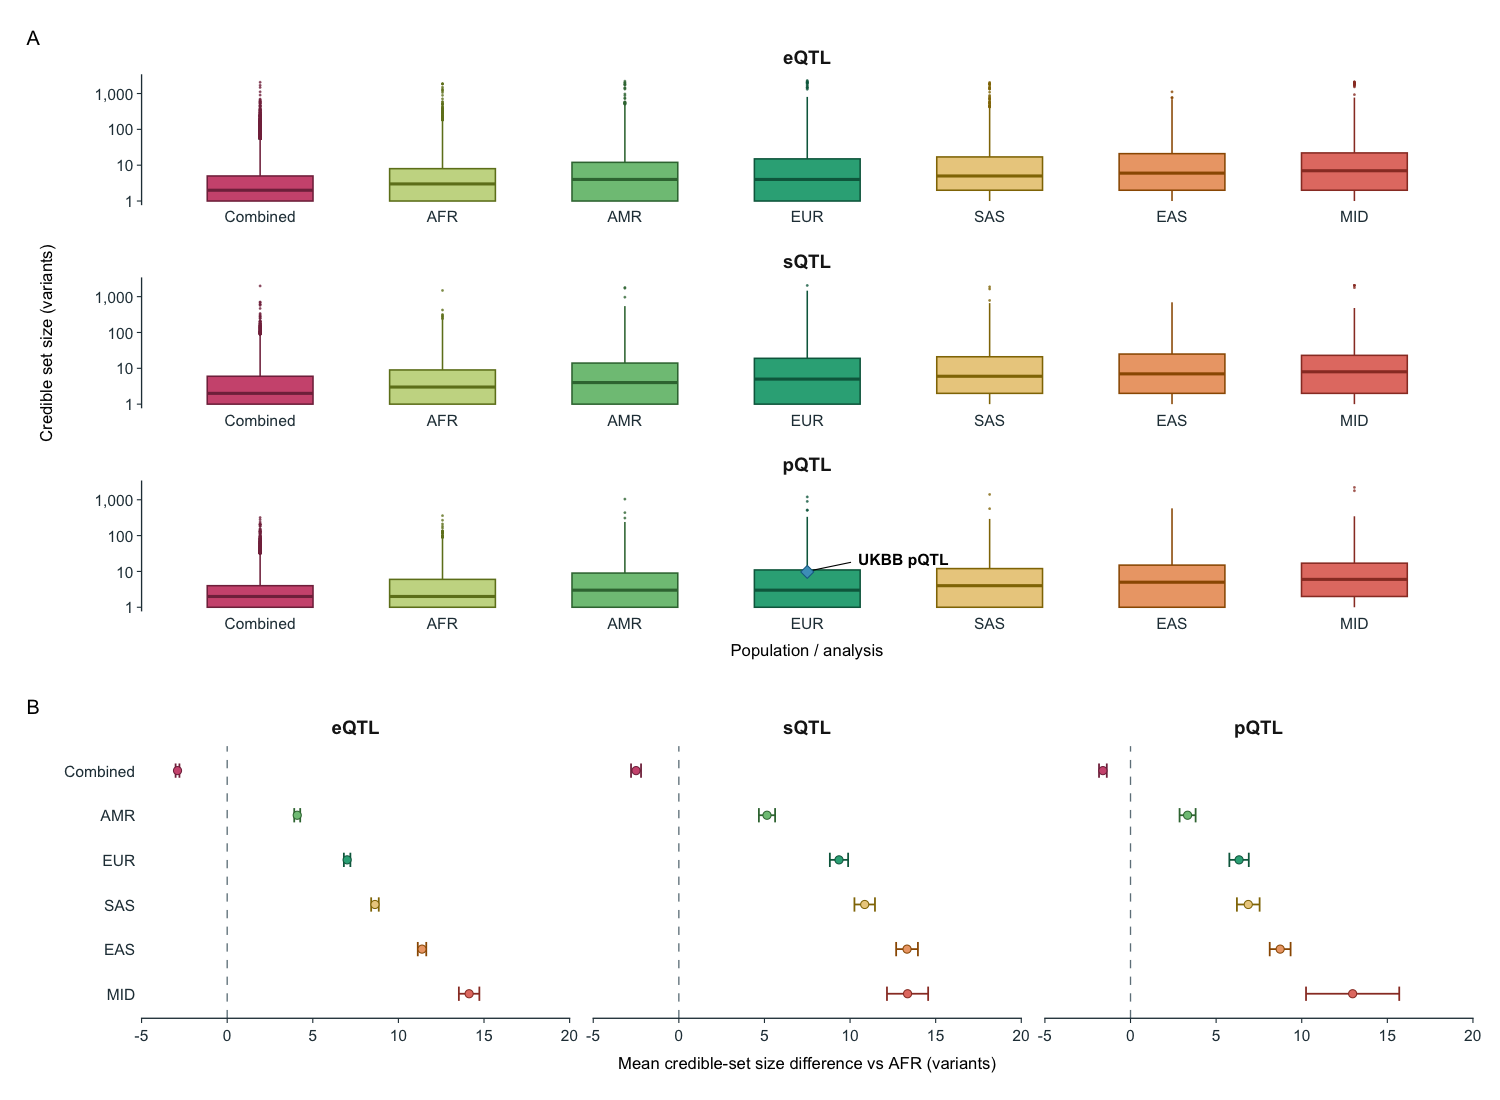

In [3]:
panel_a <- saved$A + labs(title = NULL, subtitle = NULL)
panel_b <- saved$B + labs(title = NULL, subtitle = NULL)
figure <- panel_a / panel_b + patchwork::plot_layout(heights = c(124, 63)) +
  patchwork::plot_annotation(tag_levels = "A")
print(figure)


## Save aggregate outputs

Save the plot, exact size frequencies, and saved mean contrasts. The frequency table removes credible-set identifiers. The UKBB reference marker remains in panel A.


In [4]:
save_plot(figure, "supplements/S12", 184, 195)
readr::write_tsv(saved$A$data %>% count(assay, population, cs_size, name = "credible_sets"),
                 output_file("supplements/S12_size_frequencies.tsv"))
readr::write_tsv(saved$differences, output_file("supplements/S12_AFR_contrasts.tsv"))


Export aggregate plot: supplements/S12
